# 15 — Model-choice decision sheet: power law, curved power law, moment expansion

This notebook lays out what each criterion says about the three spectral models, with and without the
Cygnus region. **It does not choose a model.** The rule below is for the reader to apply.

## Decision rule (to be applied by the reader, not by this notebook)

A more complex model (curved power law or moment expansion) is preferred over the power law **only if it
satisfies all three conditions**:

1. **More wins than losses in ΔlnZ:** clearly more samples with ΔlnZ > +1 than with ΔlnZ < −1 (criterion 1);
2. **Better held-out prediction:** it predicts the left-out points better than the power law (criterion 3);
3. **A systematic power-law residual pattern with frequency:** the stacked power-law residuals show a
   same-sign pattern across many samples (criterion 4).

Otherwise the power law is the default. **If both the curved power law and the moment expansion pass,**
prefer the one with the better held-out prediction; **if they are still tied, report a tie and do not choose**
(they have the same number of parameters).

## The three models (from `model_comparison/models.py` and `config.yaml`, unchanged)

With x = ln(ν / 408 MHz):

* **Power law:** T = A·e^(βx)
* **Curved power law:** T = A·e^(βx + Cx²)
* **Moment expansion (order 2):** T = A·e^(β̄x)·(1 + ω₁x + ω₂x²/2), with **β̄ fixed at −2.7**
  (`models.moment_beta_fixed` in `config.yaml`; the next code cell checks that the value is still −2.7)
  and ω₁, ω₂ free.

The parameter counts and prior ranges are read from `models.py` / `config.yaml` and printed below.

## Sample sets

Every criterion is computed three ways: **all 120 ring samples**; **excluding RA within ±15° of Cygnus A**
(RA 299.9°); and **excluding RA within ±25°** (the TRIS beam is about 19–23° wide, so neighbouring samples
also see Cygnus A).

## Warnings

* **The ring samples are not independent.** They are 3° apart under a ~20° beam, so neighbouring samples
  see mostly the same sky. Counts are not independent votes, and the standard errors on the stacked
  statistics (criterion 4) are **underestimates**. No summed ln Z totals are shown for the same reason.
* **Survey scale and zero-level errors are common offsets, but are treated as independent per point.**
  Each survey's published gain and zero-level errors widen its error bars at every sample, but in reality
  they shift all samples of that survey together (TODO N-15). This makes the error bars at different
  samples correlated in a way the fits ignore.

## Inputs: every evidence and every best fit comes from UltraNest

* `model_comparison/results/evidence_per_unit_tod.csv`: UltraNest ln Z per sample for all three models
  (the run of 2026-10-22, with `moment_beta_fixed = -2.7`, as `evidence_summary_tod.csv` records). Used for
  criterion 1 and for the ×1 column of criterion 5.
* `model_comparison/sky_models_408/cache/fits/unitNNN__power_law.npz` and `__curved_power_law.npz`: the
  6 fitted points per sample (ν, T, σ) and the UltraNest posteriors and best fits (notebook 12, same data,
  priors and sampler settings). Their best fits are used for criteria 2 and 4.
* **No saved moment-expansion fits exist for the 120 samples** (only 6 samples in notebook 11's cache), so the
  moment expansion is run here with UltraNest at the original error bars, to get its best fits.
* **Criterion 5 needs evidences and best fits with changed error bars,** so all three models are run here with
  UltraNest at ×0.7 and ×1.5.
* These new runs use `run_comparison.py`'s likelihood and `config.yaml`'s priors and sampler settings, seeded per
  sample, and are cached in `model_comparison/model_choice/cache/` (about 35 minutes the first time).
* **The only fits not made with UltraNest are the leave-one-point-out refits of criterion 3** (2,160 small fits),
  which are quick maximum-likelihood fits (scipy) within the same prior ranges.
* "Best fit" = the maximum-likelihood point UltraNest found.

Outputs go to `model_comparison/model_choice/`. Rerun: Restart & Run All (seconds once cached).

In [1]:
%matplotlib inline
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import logging
from scipy.optimize import least_squares

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
FIT_CACHE = MC_DIR / "sky_models_408" / "cache" / "fits"
RA_FILE = MC_DIR / "sky_models_408" / "cache" / "ring_RA.npy"
EV_CSV = MC_DIR / "results" / "evidence_per_unit_tod.csv"
SUMMARY_CSV = MC_DIR / "results" / "evidence_summary_tod.csv"
OUT_DIR = MC_DIR / "model_choice"

# ---- sample sets ----
CYG_A_RA = 299.9
EXCLUDE_HALF_WIDTHS = [None, 15.0, 25.0]      # None = all samples

# ---- reading the criteria ----
TIE = 1.0              # |dlnZ| <= 1: tie; > +1 favours the first model of the pair
BORDER = 0.4           # "borderline": within 0.4 of +/-1 (notebook 11 Part 4: sampling noise moves dlnZ by up to ~0.4)
IC_THRESHOLD = 2.0     # AIC/BIC: a difference larger than 2 counts as one model being better
LOO_TIE_FRAC = 0.05    # held-out prediction: mean z^2 within 5% of each other counts as a tie
PATTERN_NSEM = 3.0     # stacked residuals: a survey is "systematic" if its mean is > 3 standard errors from 0
PATTERN_SIGN = 0.75    #   ... and at least 75% of samples have residuals of that sign
PATTERN_MIN_SURVEYS = 2  # a residual "pattern with frequency" needs at least this many systematic surveys

# ---- error sensitivity ----
ERROR_SCALES = [0.7, 1.0, 1.5]
SCALE_TRIS_TOO = False   # False: scale only the non-TRIS surveys (see the criterion 5 note)

# ---- UltraNest runs made here (moment expansion at x1; all models at the other error scales) ----
RUN_ULTRANEST = True     # False: use the cache only
SEED = 12345             # UltraNest draws from numpy's global random generator; seeded with SEED + sample index
UN_DIR = OUT_DIR / "cache"

EXPECTED_BETA_FIXED = -2.7     # the value stated in the markdown cell above

PL, CURVED, MOMENT = "power law", "curved power law", "moment expansion (order 2)"
MODELS_ORDER = [PL, CURVED, MOMENT]
SHORT = {PL: "power law", CURVED: "curved PL", MOMENT: "moment exp."}
PAIRS = [(CURVED, PL), (MOMENT, PL), (MOMENT, CURVED)]     # (first, second): d = first - second
PAIR_LABEL = {p: f"{SHORT[p[0]]} vs {SHORT[p[1]]}" for p in PAIRS}
SURVEYS = ["LWA_35MHz.fits", "MAIPU_45mhZ.fits", "LWA_80MHz.fits", "TRIS_600", "TRIS_820",
           "STOCKERT_VILLA_1400MHZ.fits"]
SURVEY_NAME = {"LWA_35MHz.fits": "LWA 35", "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA 80",
               "TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}
# Okabe-Ito, colourblind-safe (same model colours as notebook 11)
COL = {PL: "#0072B2", CURVED: "#D55E00", MOMENT: "#009E73"}
PAIR_COL = {(CURVED, PL): "#D55E00", (MOMENT, PL): "#009E73", (MOMENT, CURVED): "#CC79A7"}
# 3-class PuOr (diverging, grey midpoint): favours first / tie / favours second
VERDICT_COL = {"first": "#b35806", "tie": "#d9d9d9", "second": "#542788"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 11.5,
                     "axes.labelsize": 10.5, "legend.fontsize": 9, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / name).relative_to(REPO)}")

## Models, priors and parameter counts, read from `models.py`

In [2]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(MC_DIR))
sys.path.insert(0, str(REPO / "src"))
from models import build_models                  # the model definitions, unchanged
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
# How the ring TODs are made (run_config.yaml sed.tod_beam, beam-matched since 2026-10-27).  Cached results
# made from other TODs do not match it and are redone.
TOD_KEY = tod_method_key(load_config(REPO / "configs" / "run_config.yaml"))

cfg = yaml.safe_load(open(MC_DIR / "config.yaml"))
# This sheet compares three models; config.yaml may list more moment orders (e.g. order 3), which are not used here.
MODELS = {m: v for m, v in build_models(cfg).items() if m in MODELS_ORDER}
PRIORS = cfg["priors"]
BETA_FIXED = cfg["models"].get("moment_beta_fixed")
assert list(MODELS) == MODELS_ORDER, list(MODELS)
assert BETA_FIXED is not None and float(BETA_FIXED) == EXPECTED_BETA_FIXED, \
    f"config.yaml now has moment_beta_fixed = {BETA_FIXED}; update the markdown cell at the top"
K = {m: len(MODELS[m][0]) for m in MODELS}

run_beta = pd.read_csv(SUMMARY_CSV)["moment_beta_fixed"].iloc[0]
print(f"moment expansion: beta fixed at {float(BETA_FIXED):g} (config.yaml); "
      f"the evidence CSV was made with moment_beta_fixed = {run_beta}")
assert str(run_beta) != "free" and float(run_beta) == float(BETA_FIXED)

rows = []
for m in MODELS:
    names = MODELS[m][0]
    rows.append({"model": m, "parameters (k)": K[m], "names": ", ".join(names),
                 "prior ranges": "; ".join(f"{n}: {PRIORS[n]['type']} [{PRIORS[n]['low']:g}, {PRIORS[n]['high']:g}]"
                                           for n in names)})
print(pd.DataFrame(rows).to_string(index=False))

moment expansion: beta fixed at -2.7 (config.yaml); the evidence CSV was made with moment_beta_fixed = -2.7
                     model  parameters (k)               names                                                                  prior ranges
                 power law               2           A_K, beta                         A_K: loguniform [1, 1000]; beta: uniform [-3.5, -1.5]
          curved power law               3        A_K, beta, C A_K: loguniform [1, 1000]; beta: uniform [-3.5, -1.5]; C: uniform [-0.5, 0.5]
moment expansion (order 2)               3 A_K, omega1, omega2   A_K: loguniform [1, 1000]; omega1: uniform [-1, 1]; omega2: uniform [-1, 1]


## Load the data and the cached evidence

In [3]:
RA = np.load(RA_FILE)
ev = pd.read_csv(EV_CSV).set_index("unit").sort_index()
UNITS = ev.index.to_numpy()
assert np.allclose(RA[UNITS], ev["ra_deg"])
DATA = {}
for u in UNITS:
    z = np.load(FIT_CACHE / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    assert "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY, \
        "notebook 12's fit cache was made from other ring TODs: rerun notebook 12 first"
    keys = [str(k) for k in z["keys"]]
    assert sorted(keys) == sorted(SURVEYS), keys
    DATA[u] = dict(nu=z["nu"].astype(float), t=z["t"].astype(float), s=z["s"].astype(float), keys=keys)
LNZ = {m: ev[f"logZ {m}"].to_numpy() for m in MODELS}
print(f"{len(UNITS)} ring samples, each with the 6 points {', '.join(SURVEY_NAME[k] for k in SURVEYS)}")

def ra_distance(ra, ref):
    return np.abs((ra - ref + 180.0) % 360.0 - 180.0)

SETS = {}
for w in EXCLUDE_HALF_WIDTHS:
    label = "all samples" if w is None else f"excl. RA {CYG_A_RA:g} ± {w:g}°"
    SETS[label] = np.ones(len(UNITS), bool) if w is None else ra_distance(ev["ra_deg"].to_numpy(), CYG_A_RA) > w
for k, v in SETS.items():
    print(f"  {k:<26} {v.sum():>3} samples")
SET_NAMES = list(SETS)

120 ring samples, each with the 6 points LWA 35, Maipu 45, LWA 80, TRIS 600, TRIS 820, Stockert 1420
  all samples                120 samples
  excl. RA 299.9 ± 15°       110 samples
  excl. RA 299.9 ± 25°       103 samples


## Best fits and evidences from UltraNest

The power law and the curved power law at the original error bars come from notebook 12's cache. Everything else
(the moment expansion at ×1, all three models at ×0.7 and ×1.5) is run here with UltraNest: the same Gaussian
likelihood as `run_comparison.py`, the priors and sampler settings of `config.yaml`, seeded. Checks: the new
moment-expansion ln Z at ×1 against the CSV (they should agree within the sampling noise of about ±0.3, notebook 11
Part 4), and UltraNest's best-fit χ² against a direct maximum-likelihood search (scipy).

In [4]:
import ultranest
SCFG = cfg["sampler"]

def prior_box(m):
    names = MODELS[m][0]
    is_log = np.array([PRIORS[n]["type"] == "loguniform" for n in names])
    lo = np.array([np.log(PRIORS[n]["low"]) if g else PRIORS[n]["low"] for n, g in zip(names, is_log)])
    hi = np.array([np.log(PRIORS[n]["high"]) if g else PRIORS[n]["high"] for n, g in zip(names, is_log)])
    return names, is_log, lo, hi

BOX = {m: prior_box(m) for m in MODELS}

def to_theta(m, x):
    _, is_log, _, _ = BOX[m]
    th = np.array(x, dtype=float, copy=True)
    th[..., is_log] = np.exp(th[..., is_log])
    return th

def scaled_s(d, scale):
    s = d["s"].copy()
    for i, k in enumerate(d["keys"]):
        if SCALE_TRIS_TOO or not k.startswith("TRIS"):
            s[i] *= scale
    return s

def run_ultranest(m, nu, t, s, seed):
    # The same likelihood and UltraNest call as run_comparison.log_evidence (models.py, config.yaml priors).
    from models import prior_transform
    names, fn = MODELS[m]
    transform = prior_transform(names, PRIORS)
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(seed)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True, log_dir=None)
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=float(res["logz"]), logzerr=float(res["logzerr"]),
                maxpoint=np.asarray(res["maximum_likelihood"]["point"], float))

def un_path(sc, m, u):
    return UN_DIR / f"unit{u:03d}__{m.replace(' ', '_').replace('(', '').replace(')', '')}__errx{sc:g}.npz"

UN = {}            # (scale, model, unit) -> dict(logz, logzerr, maxpoint, source)
todo = []
for sc in ERROR_SCALES:
    for m in MODELS:
        for u in UNITS:
            if sc == 1.0 and m in (PL, CURVED):
                z = np.load(FIT_CACHE / f"unit{u:03d}__{m.replace(' ', '_')}.npz", allow_pickle=False)
                UN[(sc, m, u)] = dict(logz=float(z["logz"]), logzerr=float(z["logzerr"]),
                                      maxpoint=z["maxpoint"].astype(float), source="notebook 12 cache")
            elif un_path(sc, m, u).exists() and str(np.load(un_path(sc, m, u)).get("tod_key", "")) == TOD_KEY:
                z = np.load(un_path(sc, m, u), allow_pickle=False)
                UN[(sc, m, u)] = dict(logz=float(z["logz"]), logzerr=float(z["logzerr"]),
                                      maxpoint=z["maxpoint"].astype(float), source="this notebook (cached)")
            else:
                todo.append((sc, m, u))
if todo and not RUN_ULTRANEST:
    raise RuntimeError(f"{len(todo)} UltraNest runs are missing from the cache; set RUN_ULTRANEST = True")
if todo:
    UN_DIR.mkdir(exist_ok=True)
    print(f"running {len(todo)} UltraNest fits...")
    for i, (sc, m, u) in enumerate(todo):
        d = DATA[u]
        r = run_ultranest(m, d["nu"], d["t"], scaled_s(d, sc), SEED + int(u))
        np.savez(un_path(sc, m, u), **r, tod_key=TOD_KEY)
        UN[(sc, m, u)] = dict(r, source="this notebook")
        if (i + 1) % 120 == 0:
            print(f"  {i + 1} of {len(todo)} done")
print(pd.Series([v["source"] for v in UN.values()]).value_counts().to_string())

# best fits (UltraNest's maximum-likelihood point) and evidences per error scale
FIT = {}
for (sc, m, u), r in UN.items():
    d = DATA[u]; fn = MODELS[m][1]
    model = fn(d["nu"], r["maxpoint"][None, :])[0]
    FIT[(sc, m, u)] = dict(theta=r["maxpoint"], model=model,
                           chi2=float(np.sum(((d["t"] - model) / scaled_s(d, sc)) ** 2)))
ULNZ = {(sc, m): (LNZ[m] if sc == 1.0 else np.array([UN[(sc, m, u)]["logz"] for u in UNITS]))
        for sc in ERROR_SCALES for m in MODELS}

diff = np.array([UN[(1.0, MOMENT, u)]["logz"] for u in UNITS]) - LNZ[MOMENT]
print(f"\nmoment expansion, ln Z run here − CSV (both UltraNest, x1): median {np.median(diff):+.3f}, "
      f"largest |difference| {np.abs(diff).max():.3f}, within 0.5 in {int((np.abs(diff) <= 0.5).sum())} of {len(diff)}")

running 840 UltraNest fits...


  120 of 840 done


  240 of 840 done


  360 of 840 done


  480 of 840 done


  600 of 840 done


  720 of 840 done


  840 of 840 done
this notebook        840
notebook 12 cache    240

moment expansion, ln Z run here − CSV (both UltraNest, x1): median +0.007, largest |difference| 0.567, within 0.5 in 117 of 120


In [5]:
# Check: UltraNest's best-fit chi2 against a direct maximum-likelihood search (scipy, same prior ranges).
# ml_fit is also used for the leave-one-point-out refits of criterion 3.
def starts(m, nu, t, s):
    # Starting points from straight/quadratic fits in log-log space, clipped into the prior box.
    x = np.log(nu / float(cfg["models"]["nu0_mhz"])); y = np.log(t); w = t / s
    lin = np.polyfit(x, y, 1, w=w); quad = np.polyfit(x, y, 2, w=w)
    if m == PL:
        out = [[lin[1], lin[0]]]
    elif m == CURVED:
        out = [[quad[2], quad[1], quad[0]], [lin[1], lin[0], 0.0]]
    else:
        b = float(BETA_FIXED)
        out = [[lin[1], lin[0] - b, w2] for w2 in (-0.3, 0.0, 0.3)] + [[lin[1], 0.0, 0.0]]
    _, _, lo, hi = BOX[m]
    eps = 1e-9 * (hi - lo)
    return [np.clip(np.array(p, float), lo + eps, hi - eps) for p in out]

def ml_fit(m, nu, t, s):
    names, fn = MODELS[m]
    _, _, lo, hi = BOX[m]
    def resid(x):
        return (t - fn(nu, to_theta(m, x)[None, :])[0]) / s
    best = None
    for x0 in starts(m, nu, t, s):
        r = least_squares(resid, x0, bounds=(lo, hi), method="trf", x_scale="jac")
        if best is None or r.cost < best.cost:
            best = r
    return dict(theta=to_theta(m, best.x), chi2=2 * best.cost)

rows = []
for sc in ERROR_SCALES:
    for m in MODELS:
        gap = np.array([FIT[(sc, m, u)]["chi2"] - ml_fit(m, DATA[u]["nu"], DATA[u]["t"], scaled_s(DATA[u], sc))["chi2"]
                        for u in UNITS])
        rows.append({"errors x": sc, "model": SHORT[m], "median χ²(UltraNest) − χ²(scipy)": np.median(gap),
                     "largest": gap.max()})
print("UltraNest best fit against a direct search (≥ 0: the direct search found an equal or slightly lower χ²)")
print(pd.DataFrame(rows).round(4).to_string(index=False))

UltraNest best fit against a direct search (≥ 0: the direct search found an equal or slightly lower χ²)
 errors x       model  median χ²(UltraNest) − χ²(scipy)  largest
      0.7   power law                            0.0000   0.0003
      0.7   curved PL                            0.0016   0.0071
      0.7 moment exp.                            0.0016   0.0071
      1.0   power law                            0.0000   0.0003
      1.0   curved PL                            0.0016   0.0055
      1.0 moment exp.                            0.0017   0.0069
      1.5   power law                            0.0000   0.0003
      1.5   curved PL                            0.0016   0.0074
      1.5 moment exp.                            0.0015   0.0050


## Criterion 1 — evidence (ΔlnZ per sample, UltraNest values from the CSV)

For each pair, ΔlnZ = ln Z(first) − ln Z(second) at every sample, counted as > +1 (favours the first model),
between −1 and +1 (tie) and < −1 (favours the second). **Borderline** counts samples within 0.4 of ±1, where
notebook 11 Part 4 found that sampling noise alone can move a sample across the line. The spread is the 16th–84th
percentile range. No totals are summed (the samples are correlated).

In [6]:
def favour_from_counts(first, second, n_first, n_second):
    if n_first > n_second:
        return f"{SHORT[first]} ({n_first} vs {n_second})"
    if n_second > n_first:
        return f"{SHORT[second]} ({n_second} vs {n_first})"
    return f"tie ({n_first} vs {n_second})"

def evidence_counts(d):
    return dict(wins=int((d > TIE).sum()), ties=int((np.abs(d) <= TIE).sum()), losses=int((d < -TIE).sum()),
                borderline=int((np.abs(np.abs(d) - TIE) <= BORDER).sum()),
                median=float(np.median(d)), p16=float(np.percentile(d, 16)), p84=float(np.percentile(d, 84)))

SUMMARY = []    # rows of the CSV summary
C1 = {}
for sname, mask in SETS.items():
    for a, b in PAIRS:
        c = evidence_counts((LNZ[a] - LNZ[b])[mask])
        C1[(sname, (a, b))] = c
        SUMMARY.append({"criterion": "1 evidence (ΔlnZ)", "sample set": sname, "n samples": int(mask.sum()),
                        "comparison": PAIR_LABEL[(a, b)],
                        "result": f"ΔlnZ > +1: {c['wins']}, |ΔlnZ| ≤ 1: {c['ties']}, ΔlnZ < −1: {c['losses']}; "
                                  f"borderline (within {BORDER} of ±1): {c['borderline']}; "
                                  f"median {c['median']:+.2f} (16–84%: {c['p16']:+.2f} to {c['p84']:+.2f})",
                        "favours": favour_from_counts(a, b, c["wins"], c["losses"])})
T1 = pd.DataFrame([{"sample set": s, "comparison": PAIR_LABEL[p], **{k: (round(v, 2) if isinstance(v, float) else v)
                     for k, v in c.items()}} for (s, p), c in C1.items()])
with pd.option_context("display.width", 200):
    print(T1.to_string(index=False))

          sample set               comparison  wins  ties  losses  borderline  median   p16   p84
         all samples   curved PL vs power law    10    99      11          25   -0.25 -0.62  0.47
         all samples moment exp. vs power law     6    45      69          59   -1.14 -1.57 -0.55
         all samples moment exp. vs curved PL     0    59      61          92   -1.02 -1.27 -0.57
excl. RA 299.9 ± 15°   curved PL vs power law     3    96      11          25   -0.31 -0.64  0.26
excl. RA 299.9 ± 15° moment exp. vs power law     0    42      68          58   -1.24 -1.63 -0.68
excl. RA 299.9 ± 15° moment exp. vs curved PL     0    56      54          87   -0.99 -1.22 -0.59
excl. RA 299.9 ± 25°   curved PL vs power law     1    94       8          23   -0.32 -0.62  0.24
excl. RA 299.9 ± 25° moment exp. vs power law     0    38      65          56   -1.25 -1.57 -0.72
excl. RA 299.9 ± 25° moment exp. vs curved PL     0    51      52          84   -1.02 -1.22 -0.62


## Criterion 2 — fit quality: χ², AIC and BIC per sample

From UltraNest's best fits (maximum-likelihood points). With N = 6 points per sample and k parameters (power law k = 2, curved power
law k = 3, moment expansion k = 3, read from `models.py` above): AIC = χ² + 2k, BIC = χ² + k ln N. (The
constant terms of −2 ln L are the same for every model at a given sample, so they cancel in the differences.)
For each pair, ΔAIC and ΔBIC = first − second; a value below −2 means the first model is better, above +2 the
second.

In [7]:
N_PTS = 6
CHI = {m: np.array([FIT[(1.0, m, u)]["chi2"] for u in UNITS]) for m in MODELS}
AIC = {m: CHI[m] + 2 * K[m] for m in MODELS}
BIC = {m: CHI[m] + K[m] * np.log(N_PTS) for m in MODELS}
print("parameter counts used:", ", ".join(f"{SHORT[m]} k = {K[m]}" for m in MODELS), f"; N = {N_PTS} points")

C2 = {}
for sname, mask in SETS.items():
    for m in MODELS:
        SUMMARY.append({"criterion": "2 fit quality (χ²)", "sample set": sname, "n samples": int(mask.sum()),
                        "comparison": SHORT[m],
                        "result": f"best-fit χ² median {np.median(CHI[m][mask]):.2f} "
                                  f"(16–84%: {np.percentile(CHI[m][mask], 16):.2f} to {np.percentile(CHI[m][mask], 84):.2f}), "
                                  f"k = {K[m]}, dof = {N_PTS - K[m]}",
                        "favours": "(not a comparison; see AIC/BIC rows)"})
    for a, b in PAIRS:
        for ic_name, IC in (("AIC", AIC), ("BIC", BIC)):
            d = (IC[a] - IC[b])[mask]
            better_first, better_second = int((d < -IC_THRESHOLD).sum()), int((d > IC_THRESHOLD).sum())
            C2[(sname, (a, b), ic_name)] = dict(first=better_first, within=int((np.abs(d) <= IC_THRESHOLD).sum()),
                                                 second=better_second, median=float(np.median(d)))
            SUMMARY.append({"criterion": f"2 fit quality ({ic_name})", "sample set": sname, "n samples": int(mask.sum()),
                            "comparison": PAIR_LABEL[(a, b)],
                            "result": f"Δ{ic_name} (first − second) < −2: {better_first}, within ±2: "
                                      f"{C2[(sname, (a, b), ic_name)]['within']}, > +2: {better_second}; "
                                      f"median Δ{ic_name} {np.median(d):+.2f}",
                            "favours": favour_from_counts(a, b, better_first, better_second)})
T2 = pd.DataFrame([{"sample set": s, "comparison": PAIR_LABEL[p], "criterion": ic, **c} for (s, p, ic), c in C2.items()])
with pd.option_context("display.width", 200):
    print(T2.round(2).to_string(index=False))

parameter counts used: power law k = 2, curved PL k = 3, moment exp. k = 3 ; N = 6 points
          sample set               comparison criterion  first  within  second  median
         all samples   curved PL vs power law       AIC     26      94       0   -1.01
         all samples   curved PL vs power law       BIC     28      92       0   -1.22
         all samples moment exp. vs power law       AIC     21      99       0   -0.54
         all samples moment exp. vs power law       BIC     23      97       0   -0.75
         all samples moment exp. vs curved PL       AIC      0     120       0    0.47
         all samples moment exp. vs curved PL       BIC      0     120       0    0.47
excl. RA 299.9 ± 15°   curved PL vs power law       AIC     18      92       0   -0.55
excl. RA 299.9 ± 15°   curved PL vs power law       BIC     20      90       0   -0.76
excl. RA 299.9 ± 15° moment exp. vs power law       AIC     13      97       0   -0.04
excl. RA 299.9 ± 15° moment exp. vs powe

## Criterion 3 — predictive check (leave one point out)

At every sample, each of the 6 points is left out in turn; each model is refitted by maximum likelihood to the
other 5 and predicts the missing point. The **standardised error** is z = (data − prediction) / σ of that point
(the prediction's own uncertainty is not added). A model predicts better when its **mean z²** is lower; the
**median |z|** is shown too, because the mean z² is dominated by the points with the smallest error bars (TRIS 600,
whose σ is about 0.07 K, and Maipu 45). Leaving
out LWA 35 or Stockert 1420 means extrapolating beyond the remaining points, which is a harder test than leaving
out a point in the middle.

In [8]:
LOO = []   # one row per (unit, left-out survey, model)
for u in UNITS:
    d = DATA[u]
    for i, key in enumerate(d["keys"]):
        keep = np.arange(len(d["t"])) != i
        for m in MODELS:
            f = ml_fit(m, d["nu"][keep], d["t"][keep], d["s"][keep])
            pred = MODELS[m][1](d["nu"][i:i + 1], f["theta"][None, :])[0][0]
            LOO.append({"unit": u, "survey": key, "model": m, "z": (d["t"][i] - pred) / d["s"][i]})
LOO = pd.DataFrame(LOO)
LOO.to_csv(OUT_DIR / "loo_standardised_errors.csv", index=False)

def loo_table(mask, stat="mean z2"):
    sub = LOO[LOO["unit"].isin(UNITS[mask])]
    f = (lambda z: float(np.mean(z ** 2))) if stat == "mean z2" else (lambda z: float(np.median(np.abs(z))))
    rows = {}
    for key in ["all points"] + SURVEYS:
        s2 = sub if key == "all points" else sub[sub["survey"] == key]
        rows[key if key == "all points" else SURVEY_NAME[key]] = {m: f(s2[s2["model"] == m]["z"].to_numpy())
                                                                  for m in MODELS}
    return pd.DataFrame(rows).T

def loo_favour(a, b, za, zb):
    if abs(za - zb) <= LOO_TIE_FRAC * min(za, zb):
        return f"tie (mean z² {za:.2f} vs {zb:.2f})"
    return (f"{SHORT[a]} (mean z² {za:.2f} vs {zb:.2f})" if za < zb else f"{SHORT[b]} (mean z² {zb:.2f} vs {za:.2f})")

C3 = {}
for sname, mask in SETS.items():
    tab = loo_table(mask)
    med = loo_table(mask, "median |z|")
    C3[sname] = tab
    print(f"\n{sname}: left-out point, mean z² | median |z|  (lower = better prediction)")
    print(pd.concat([tab.rename(columns=lambda m: f"{SHORT[m]} mean z²"),
                     med.rename(columns=lambda m: f"{SHORT[m]} median |z|")], axis=1).round(2).to_string())
    for a, b in PAIRS:
        for row in tab.index:
            SUMMARY.append({"criterion": "3 held-out prediction" + ("" if row == "all points" else f" ({row})"),
                            "sample set": sname, "n samples": int(mask.sum()), "comparison": PAIR_LABEL[(a, b)],
                            "result": f"mean z²: {SHORT[a]} {tab.loc[row, a]:.2f}, {SHORT[b]} {tab.loc[row, b]:.2f}; "
                                      f"median |z|: {SHORT[a]} {med.loc[row, a]:.2f}, {SHORT[b]} {med.loc[row, b]:.2f}",
                            "favours": loo_favour(a, b, tab.loc[row, a], tab.loc[row, b])})


all samples: left-out point, mean z² | median |z|  (lower = better prediction)
               power law mean z²  curved PL mean z²  moment exp. mean z²  power law median |z|  curved PL median |z|  moment exp. median |z|
all points                 90.35              22.50                39.10                  1.16                  0.59                    0.93
LWA 35                      0.45               0.96                 1.59                  0.30                  0.65                    1.03
Maipu 45                  143.32              91.84               111.51                  9.65                  5.95                    7.59
LWA 80                      0.73               0.19                 0.25                  0.83                  0.29                    0.24
TRIS 600                  394.50              41.73               120.57                 18.40                  4.83                   10.23
TRIS 820                    2.45               0.26                 0.63  

## Criterion 4 — stacked residuals against frequency

For each model's best fit, the standardised residual (data − model)/σ of every survey, stacked over the samples:
the mean and its standard error (std / √n — an **underestimate**, the samples are correlated). A survey is called
**systematic** when its mean is more than 3 standard errors from zero **and** at least 75% of the samples have a
residual of that sign. A **pattern with frequency** means at least 2 systematic surveys. These thresholds are set in
the settings cell. For the power law, a pattern means curvature may be needed; for the other two models, it shows
what is left after the extra parameter.

In [9]:
def stacked(sc, m, mask):
    z = np.array([(DATA[u]["t"] - FIT[(sc, m, u)]["model"]) / scaled_s(DATA[u], sc) for u in UNITS[mask]])
    order = [DATA[UNITS[0]]["keys"].index(k) for k in SURVEYS]
    z = z[:, order]
    n = len(z)
    mean, sem = z.mean(0), z.std(0, ddof=1) / np.sqrt(n)
    same_sign = np.where(mean >= 0, (z > 0).mean(0), (z < 0).mean(0))
    systematic = (np.abs(mean) > PATTERN_NSEM * sem) & (same_sign >= PATTERN_SIGN)
    return dict(mean=mean, sem=sem, same_sign=same_sign, systematic=systematic,
                pattern=int(systematic.sum()) >= PATTERN_MIN_SURVEYS)

NU_OF = {k: float(np.mean([DATA[u]["nu"][DATA[u]["keys"].index(k)] for u in UNITS])) for k in SURVEYS}
C4 = {(sc, m, s): stacked(sc, m, mask) for sc in ERROR_SCALES for m in MODELS for s, mask in SETS.items()}

def pattern_text(r):
    sys_ = [f"{SURVEY_NAME[k]} {r['mean'][i]:+.2f}±{r['sem'][i]:.2f} ({100 * r['same_sign'][i]:.0f}% same sign)"
            for i, k in enumerate(SURVEYS) if r["systematic"][i]]
    return (f"{int(r['systematic'].sum())} systematic survey(s)" + (": " + "; ".join(sys_) if sys_ else ""))

rows = []
for (sc, m, sname), r in C4.items():
    for i, k in enumerate(SURVEYS):
        rows.append({"error scale": sc, "model": m, "sample set": sname, "survey": SURVEY_NAME[k],
                     "frequency [MHz]": NU_OF[k], "mean z": r["mean"][i], "standard error": r["sem"][i],
                     "fraction with this sign": r["same_sign"][i], "systematic": bool(r["systematic"][i])})
pd.DataFrame(rows).to_csv(OUT_DIR / "stacked_residuals.csv", index=False)

for sname in SET_NAMES:
    for m in MODELS:
        r = C4[(1.0, m, sname)]
        fav = (("curvature needed (power-law residuals have a pattern)" if r["pattern"] else
                "power law (no pattern in its residuals)") if m == PL else
               ("pattern remains" if r["pattern"] else "no pattern remains"))
        SUMMARY.append({"criterion": "4 stacked residuals", "sample set": sname, "n samples": int(SETS[sname].sum()),
                        "comparison": f"{SHORT[m]} residuals", "result": pattern_text(r), "favours": fav})
    print(f"\n{sname}")
    tab = pd.DataFrame({SHORT[m]: [f"{C4[(1.0, m, sname)]['mean'][i]:+.2f} ± {C4[(1.0, m, sname)]['sem'][i]:.2f}"
                                   + (" *" if C4[(1.0, m, sname)]["systematic"][i] else "") for i in range(len(SURVEYS))]
                        for m in MODELS}, index=[SURVEY_NAME[k] for k in SURVEYS])
    print(tab.to_string())
print("\n* = systematic (mean > 3 standard errors from 0 and ≥ 75% of samples with that sign)")


all samples
                    power law       curved PL     moment exp.
LWA 35         +0.27 ± 0.06 *  +0.66 ± 0.06 *  +0.85 ± 0.06 *
Maipu 45       -0.12 ± 0.01 *  -0.07 ± 0.01 *  -0.09 ± 0.01 *
LWA 80         +0.79 ± 0.03 *    +0.17 ± 0.02    +0.10 ± 0.03
TRIS 600       +0.13 ± 0.00 *    +0.01 ± 0.00  +0.03 ± 0.00 *
TRIS 820       -1.46 ± 0.05 *  -0.16 ± 0.01 *  -0.39 ± 0.02 *
Stockert 1420  -0.74 ± 0.03 *  +0.10 ± 0.01 *    -0.05 ± 0.01

excl. RA 299.9 ± 15°
                    power law       curved PL     moment exp.
LWA 35         +0.29 ± 0.06 *  +0.68 ± 0.06 *  +0.85 ± 0.06 *
Maipu 45       -0.12 ± 0.01 *  -0.07 ± 0.01 *  -0.09 ± 0.01 *
LWA 80         +0.80 ± 0.03 *    +0.18 ± 0.03    +0.13 ± 0.03
TRIS 600       +0.12 ± 0.00 *    +0.01 ± 0.00  +0.03 ± 0.00 *
TRIS 820       -1.37 ± 0.04 *  -0.17 ± 0.02 *  -0.40 ± 0.02 *
Stockert 1420  -0.66 ± 0.02 *  +0.11 ± 0.01 *    -0.04 ± 0.01

excl. RA 299.9 ± 25°
                    power law       curved PL     moment exp.
LWA 35       

## Criterion 5 — sensitivity to the error bars

Criteria 1 and 4 repeated with the **non-TRIS survey errors** (LWA, Maipu, Stockert) multiplied by 0.7 and by 1.5.
TRIS keeps its own errors: scaling every error bar by the same factor would leave every best fit unchanged
and only rescale the residuals, so it would test nothing (set `SCALE_TRIS_TOO = True` to do it anyway). Every
evidence is from UltraNest: ×1 from the CSV (the same numbers as criterion 1), ×0.7 and ×1.5 from the runs above.

In [10]:
C5 = {}
for sname, mask in SETS.items():
    for sc in ERROR_SCALES:
        for a, b in PAIRS:
            c = evidence_counts((ULNZ[(sc, a)] - ULNZ[(sc, b)])[mask])
            C5[(sname, sc, (a, b))] = c
            SUMMARY.append({"criterion": f"5 error sensitivity: evidence, errors x{sc:g}", "sample set": sname,
                            "n samples": int(mask.sum()), "comparison": PAIR_LABEL[(a, b)],
                            "result": f"ΔlnZ > +1: {c['wins']}, |ΔlnZ| ≤ 1: {c['ties']}, ΔlnZ < −1: {c['losses']}; "
                                      f"borderline: {c['borderline']}; median {c['median']:+.2f} (UltraNest)",
                            "favours": favour_from_counts(a, b, c["wins"], c["losses"])})
        for m in MODELS:
            r = C4[(sc, m, sname)]
            fav = (("curvature needed (power-law residuals have a pattern)" if r["pattern"] else
                    "power law (no pattern in its residuals)") if m == PL else
                   ("pattern remains" if r["pattern"] else "no pattern remains"))
            SUMMARY.append({"criterion": f"5 error sensitivity: stacked residuals, errors x{sc:g}", "sample set": sname,
                            "n samples": int(mask.sum()), "comparison": f"{SHORT[m]} residuals",
                            "result": pattern_text(r), "favours": fav})
T5 = pd.DataFrame([{"sample set": s, "errors x": sc, "comparison": PAIR_LABEL[p], "> +1": c["wins"],
                    "tie": c["ties"], "< −1": c["losses"], "borderline": c["borderline"], "median": round(c["median"], 2)}
                   for (s, sc, p), c in C5.items()])
with pd.option_context("display.width", 200):
    print(T5.to_string(index=False))

          sample set  errors x               comparison  > +1  tie  < −1  borderline  median
         all samples       0.7   curved PL vs power law    21   89    10          34    0.03
         all samples       0.7 moment exp. vs power law     8   52    60          56   -1.01
         all samples       0.7 moment exp. vs curved PL     0   48    72          82   -1.07
         all samples       1.0   curved PL vs power law    10   99    11          25   -0.25
         all samples       1.0 moment exp. vs power law     6   45    69          59   -1.14
         all samples       1.0 moment exp. vs curved PL     0   59    61          92   -1.02
         all samples       1.5   curved PL vs power law    10  102     8          26   -0.26
         all samples       1.5 moment exp. vs power law     6   44    70          80   -1.12
         all samples       1.5 moment exp. vs curved PL     0   88    32          85   -0.81
excl. RA 299.9 ± 15°       0.7   curved PL vs power law    13   87    

## Figure 1 — the decision sheet
One row per sample set, one column per criterion. **Evidence and AIC/BIC:** bars split the samples into favours the
first model (orange), tie (grey) and favours the second (purple); the number of borderline samples is written next
to each evidence bar. **Held-out prediction:** mean z² of the left-out point per survey and overall (lower is better).
**Stacked residuals:** mean (data − model)/σ per survey with standard errors, filled markers are systematic.
**Error sensitivity:** samples with ΔlnZ > +1 (solid) and < −1 (dashed) against the error scale.

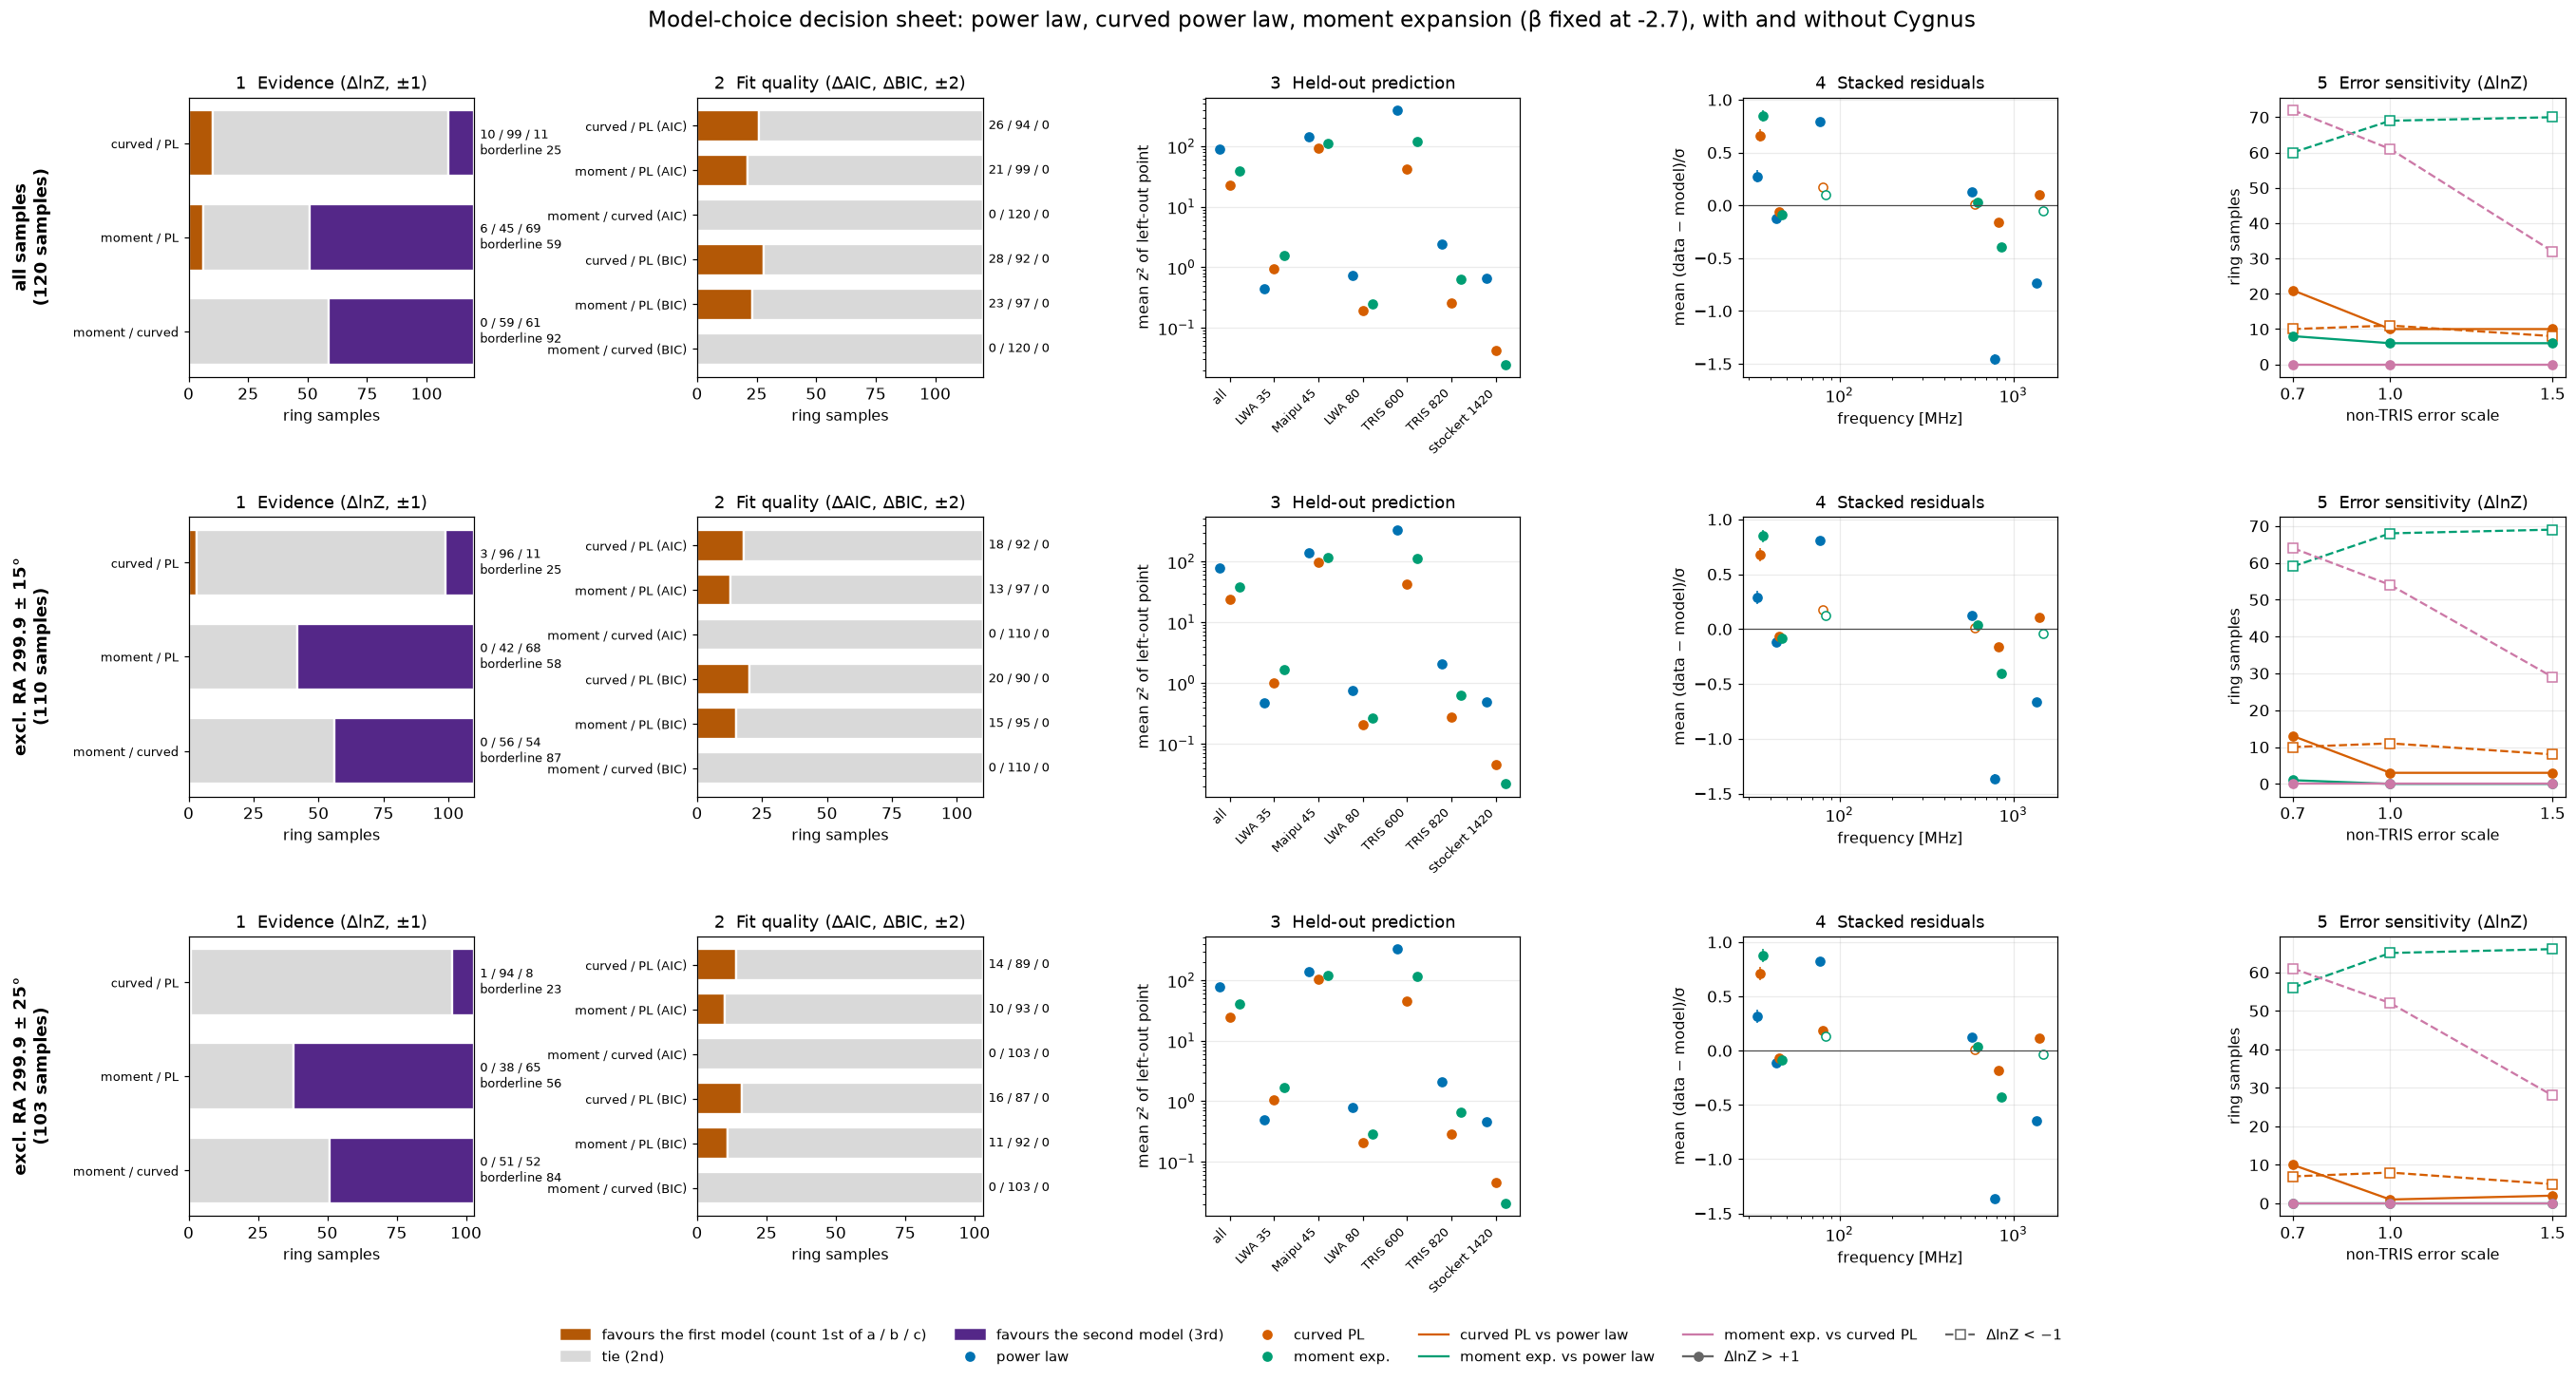

saved model_comparison/model_choice/decision_sheet.png


In [11]:
def verdict_bars(ax, items, title, border=None):
    # items: list of (label, n_first, n_tie, n_second); counts written to the right of each bar
    y = np.arange(len(items))[::-1]
    for i, (yi, (lab, a, t, b)) in enumerate(zip(y, items)):
        left = 0
        for n, key in ((a, "first"), (t, "tie"), (b, "second")):
            ax.barh(yi, n, left=left, color=VERDICT_COL[key], edgecolor="white", linewidth=1.5, height=0.7)
            left += n
        txt = f"{a} / {t} / {b}" + (f"\nborderline {border[i]}" if border is not None else "")
        ax.text(1.02, yi, txt, transform=ax.get_yaxis_transform(), va="center", fontsize=8.5)
    ax.set_yticks(y); ax.set_yticklabels([it[0] for it in items], fontsize=8.5)
    ax.set_xlim(0, sum(items[0][1:])); ax.set_title(title)

SHEET_LABEL = {(CURVED, PL): "curved / PL", (MOMENT, PL): "moment / PL", (MOMENT, CURVED): "moment / curved"}
fig, axes = plt.subplots(len(SET_NAMES), 5, figsize=(25, 4.3 * len(SET_NAMES)),
                         gridspec_kw=dict(width_ratios=[1.0, 1.0, 1.1, 1.1, 1.0], wspace=0.75, hspace=0.5))
xs = np.arange(len(SURVEYS) + 1)
for r_, sname in enumerate(SET_NAMES):
    ax = axes[r_, 0]
    items = [(SHEET_LABEL[p], C1[(sname, p)]["wins"], C1[(sname, p)]["ties"], C1[(sname, p)]["losses"]) for p in PAIRS]
    verdict_bars(ax, items, "1  Evidence (ΔlnZ, ±1)", [C1[(sname, p)]["borderline"] for p in PAIRS])
    ax.set_xlabel("ring samples")
    ax.text(-0.55, 0.5, f"{sname}\n({int(SETS[sname].sum())} samples)", transform=ax.transAxes, rotation=90,
            ha="center", va="center", fontsize=12, fontweight="bold")

    ax = axes[r_, 1]
    items = [(f"{SHEET_LABEL[p]} ({ic})", C2[(sname, p, ic)]["first"], C2[(sname, p, ic)]["within"],
              C2[(sname, p, ic)]["second"]) for ic in ("AIC", "BIC") for p in PAIRS]
    verdict_bars(ax, items, "2  Fit quality (ΔAIC, ΔBIC, ±2)")
    ax.set_xlabel("ring samples")

    ax = axes[r_, 2]
    tab = C3[sname]
    for j, m in enumerate(MODELS):
        ax.plot(xs + (j - 1) * 0.22, tab[m].to_numpy(), "o", color=COL[m], ms=6, label=SHORT[m])
    ax.set_xticks(xs); ax.set_xticklabels(["all"] + [SURVEY_NAME[k] for k in SURVEYS], rotation=45, ha="right", fontsize=8.5)
    ax.set_yscale("log"); ax.set_ylabel("mean z² of left-out point"); ax.set_title("3  Held-out prediction")
    ax.grid(alpha=0.25, axis="y")

    ax = axes[r_, 3]
    for j, m in enumerate(MODELS):
        rr = C4[(1.0, m, sname)]
        f = np.array([NU_OF[k] for k in SURVEYS]) * (1 + (j - 1) * 0.04)
        ax.errorbar(f, rr["mean"], yerr=rr["sem"], fmt="none", ecolor=COL[m], elinewidth=1)
        for fi, mi, si in zip(f, rr["mean"], rr["systematic"]):
            ax.plot(fi, mi, "o", color=COL[m], mfc=COL[m] if si else "white", ms=6)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_xscale("log"); ax.set_xlabel("frequency [MHz]"); ax.set_ylabel("mean (data − model)/σ")
    ax.set_title("4  Stacked residuals"); ax.grid(alpha=0.25)

    ax = axes[r_, 4]
    for p in PAIRS:
        w = [C5[(sname, sc, p)]["wins"] for sc in ERROR_SCALES]
        l = [C5[(sname, sc, p)]["losses"] for sc in ERROR_SCALES]
        ax.plot(ERROR_SCALES, w, "o-", color=PAIR_COL[p], label=f"{PAIR_LABEL[p]}: > +1")
        ax.plot(ERROR_SCALES, l, "s--", color=PAIR_COL[p], mfc="white", label=f"{PAIR_LABEL[p]}: < −1")
    ax.set_xticks(ERROR_SCALES); ax.set_xlabel("non-TRIS error scale"); ax.set_ylabel("ring samples")
    ax.set_title("5  Error sensitivity (ΔlnZ)"); ax.grid(alpha=0.25)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
h1 = [Patch(color=VERDICT_COL["first"], label="favours the first model (count 1st of a / b / c)"),
      Patch(color=VERDICT_COL["tie"], label="tie (2nd)"),
      Patch(color=VERDICT_COL["second"], label="favours the second model (3rd)")]
h2 = [Line2D([], [], marker="o", ls="", color=COL[m], label=SHORT[m]) for m in MODELS]
h3 = [Line2D([], [], color=PAIR_COL[p], label=PAIR_LABEL[p]) for p in PAIRS] + \
     [Line2D([], [], color="0.4", marker="o", label="ΔlnZ > +1"), Line2D([], [], color="0.4", ls="--", marker="s", mfc="white", label="ΔlnZ < −1")]
fig.legend(handles=h1 + h2 + h3, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=10)
fig.suptitle("Model-choice decision sheet: power law, curved power law, moment expansion (β fixed at "
             f"{float(BETA_FIXED):g}), with and without Cygnus", fontsize=15, y=0.995)
fig.subplots_adjust(bottom=0.1, left=0.07, right=0.98, top=0.93)
save(fig, "decision_sheet.png")

## Figure 2 — stacked residuals against frequency, in detail
Each panel is one model (columns) and sample set (rows). Points are the mean standardised residual per survey with
its standard error (an underestimate, the samples are correlated), for the original error bars and with the non-TRIS
errors ×0.7 and ×1.5. Filled markers are systematic surveys; a run of same-sign points across frequency is the
pattern criterion 4 looks for.

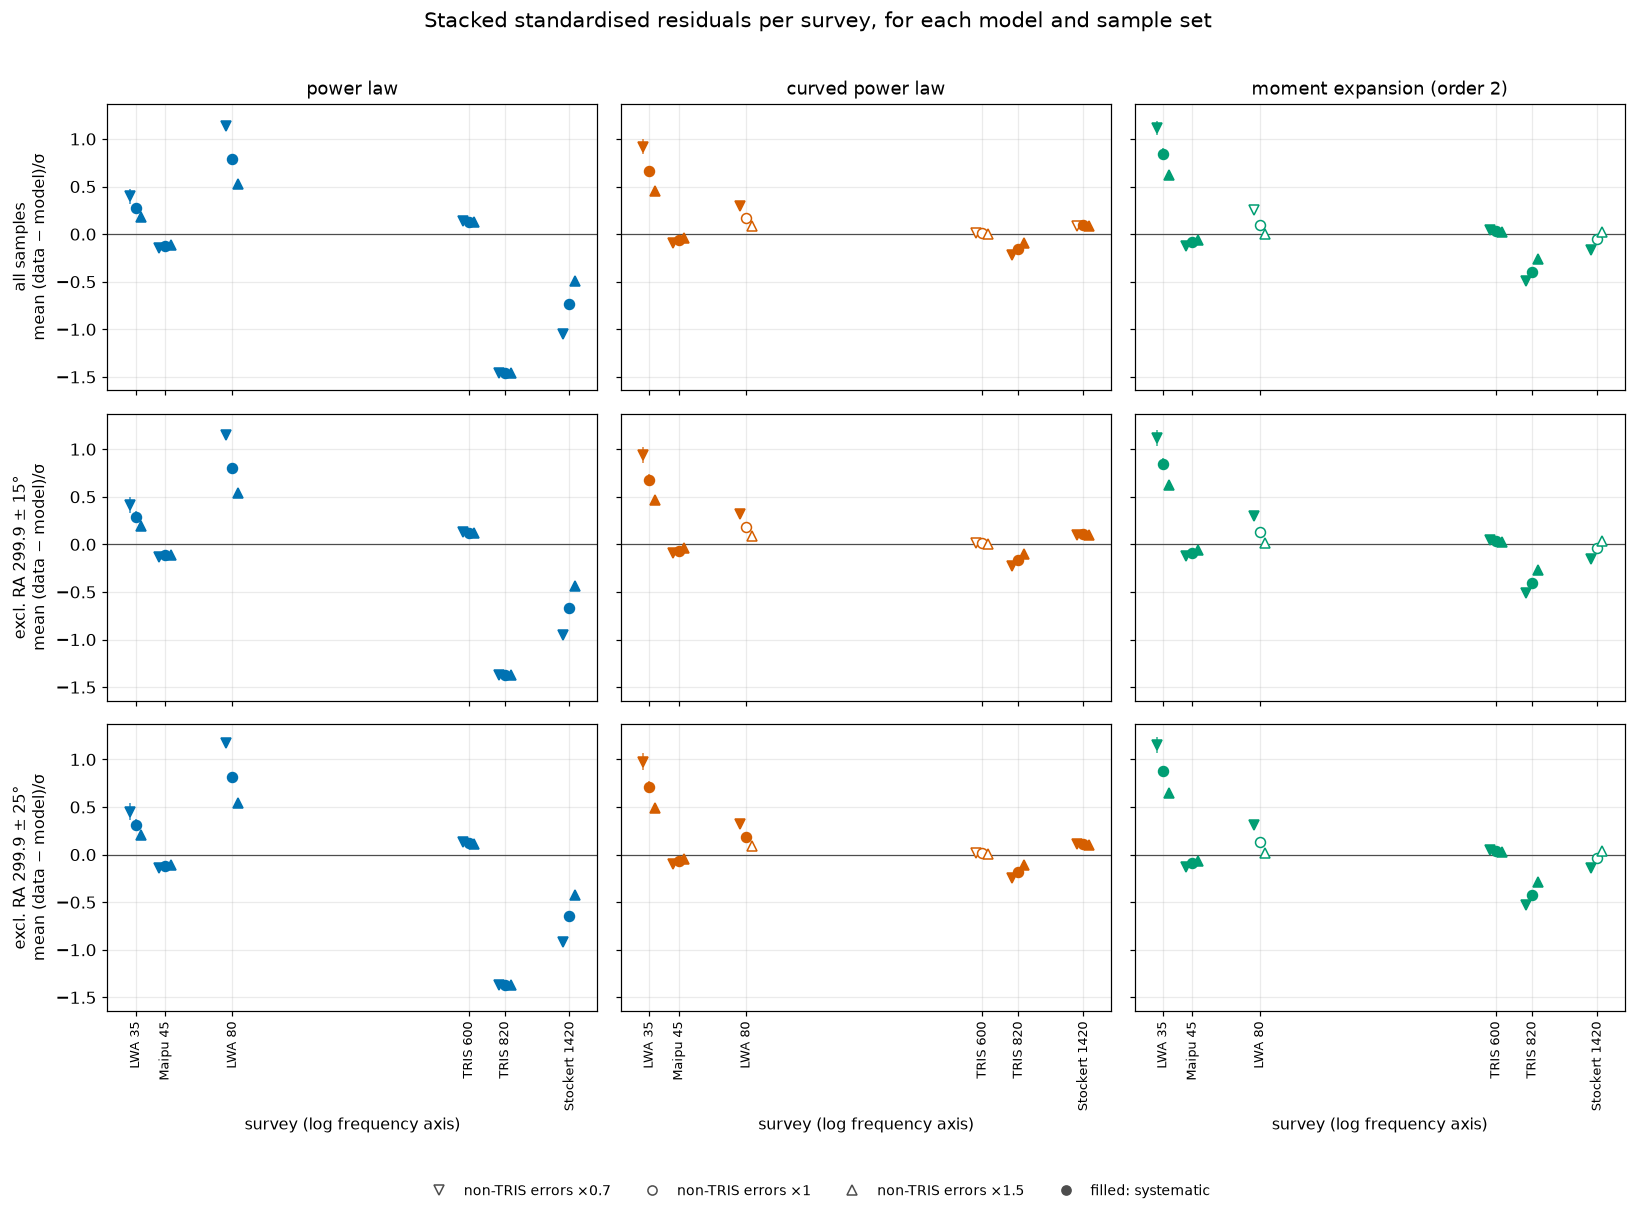

saved model_comparison/model_choice/stacked_residuals_vs_freq.png


In [12]:
SC_MARK = {0.7: "v", 1.0: "o", 1.5: "^"}
fig, axes = plt.subplots(len(SET_NAMES), len(MODELS), figsize=(15, 3.6 * len(SET_NAMES)), sharex=True, sharey=True)
for r_, sname in enumerate(SET_NAMES):
    for c_, m in enumerate(MODELS):
        ax = axes[r_, c_]
        ax.axhline(0, color="0.3", lw=0.8)
        for j, sc in enumerate(ERROR_SCALES):
            rr = C4[(sc, m, sname)]
            f = np.array([NU_OF[k] for k in SURVEYS]) * (1 + (j - 1) * 0.05)
            ax.errorbar(f, rr["mean"], yerr=rr["sem"], fmt="none", ecolor=COL[m], elinewidth=1, alpha=0.8)
            for fi, mi, si in zip(f, rr["mean"], rr["systematic"]):
                ax.plot(fi, mi, SC_MARK[sc], color=COL[m], mfc=COL[m] if si else "white", ms=6.5)
        ax.set_xscale("log"); ax.grid(alpha=0.25)
        if r_ == 0:
            ax.set_title(f"{m}", fontsize=12)
        if c_ == 0:
            ax.set_ylabel(f"{sname}\nmean (data − model)/σ")
        ax.set_xticks([NU_OF[k] for k in SURVEYS]); ax.minorticks_off()
        ax.set_xticklabels([SURVEY_NAME[k] for k in SURVEYS], rotation=90, fontsize=8.5)
        if r_ == len(SET_NAMES) - 1:
            ax.set_xlabel("survey (log frequency axis)")
handles = [Line2D([], [], marker=SC_MARK[sc], ls="", color="0.3", mfc="white", label=f"non-TRIS errors ×{sc:g}")
           for sc in ERROR_SCALES] + [Line2D([], [], marker="o", ls="", color="0.3", label="filled: systematic")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Stacked standardised residuals per survey, for each model and sample set", fontsize=14)
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
save(fig, "stacked_residuals_vs_freq.png")

## Figure 3 — ΔlnZ along the ring, with the Cygnus windows
ΔlnZ for each pair at every sample (UltraNest values from the CSV). The darker shading is ±15° around Cygnus A, the
lighter ±25°; the grey band is the tie range and the hatched strips the borderline zones within 0.4 of ±1.

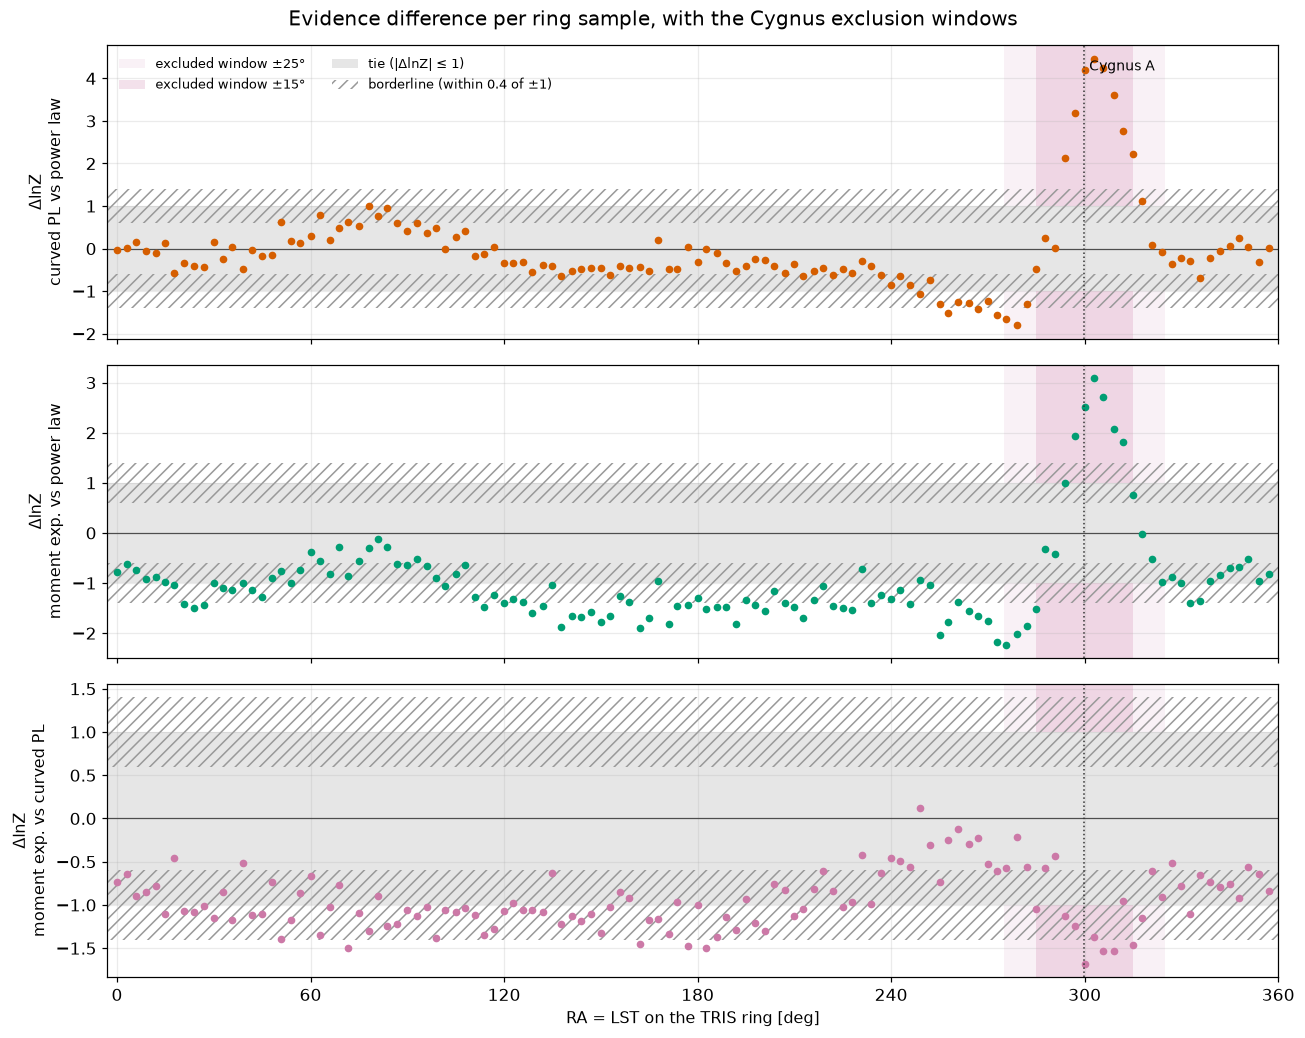

saved model_comparison/model_choice/dlnZ_vs_RA_with_windows.png


In [13]:
ra = ev["ra_deg"].to_numpy()
fig, axes = plt.subplots(len(PAIRS), 1, figsize=(12, 3.2 * len(PAIRS)), sharex=True)
for ax, (a, b) in zip(axes, PAIRS):
    d = LNZ[a] - LNZ[b]
    for w, alpha in ((25.0, 0.10), (15.0, 0.22)):
        ax.axvspan(CYG_A_RA - w, CYG_A_RA + w, color="#CC79A7", alpha=alpha, lw=0,
                   label=f"excluded window ±{w:g}°")
    ax.axhspan(-TIE, TIE, color="0.9", lw=0, label="tie (|ΔlnZ| ≤ 1)")
    for c in (-TIE, TIE):
        ax.axhspan(c - BORDER, c + BORDER, facecolor="none", edgecolor="0.6", hatch="///", lw=0,
                   label="borderline (within 0.4 of ±1)" if c > 0 else None)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.plot(ra, d, "o", ms=4, color=PAIR_COL[(a, b)])
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1)
    ax.set_ylabel(f"ΔlnZ\n{PAIR_LABEL[(a, b)]}")
    ax.grid(alpha=0.25)
axes[0].text(CYG_A_RA + 1.5, 0.95, "Cygnus A", transform=axes[0].get_xaxis_transform(), va="top", fontsize=9)
axes[0].legend(loc="upper left", ncol=2, frameon=False, fontsize=8.5)
axes[-1].set_xlabel("RA = LST on the TRIS ring [deg]")
axes[-1].set_xlim(-3, 360); axes[-1].set_xticks(np.arange(0, 361, 60))
fig.suptitle("Evidence difference per ring sample, with the Cygnus exclusion windows", fontsize=13)
fig.tight_layout()
save(fig, "dlnZ_vs_RA_with_windows.png")

## Summary table
One row per criterion, sample set and comparison; the `favours` column says, in plain language, which model that
row alone favours (or "tie"). The rules behind `favours` are the thresholds in the settings cell. Applying the
decision rule at the top is left to the reader.

In [14]:
S = pd.DataFrame(SUMMARY)
S.to_csv(OUT_DIR / "decision_summary.csv", index=False)
print(f"saved {(OUT_DIR / 'decision_summary.csv').relative_to(REPO)}  ({len(S)} rows)")
per_sample = pd.DataFrame({"unit": UNITS, "ra_deg": ev["ra_deg"].to_numpy(),
                           **{f"in: {s}": SETS[s] for s in SET_NAMES},
                           **{f"lnZ {m} (CSV)": LNZ[m] for m in MODELS},
                           **{f"chi2 {m}": CHI[m] for m in MODELS},
                           **{f"AIC {m}": AIC[m] for m in MODELS}, **{f"BIC {m}": BIC[m] for m in MODELS},
                           **{f"UltraNest lnZ {m} (non-TRIS errors x{sc:g})": ULNZ[(sc, m)] for sc in ERROR_SCALES for m in MODELS}})
per_sample.to_csv(OUT_DIR / "per_sample_values.csv", index=False)
print(f"saved {(OUT_DIR / 'per_sample_values.csv').relative_to(REPO)}")
show = S[~S["criterion"].str.startswith("3 held-out prediction (") & ~S["criterion"].str.startswith("2 fit quality (χ²)")]
with pd.option_context("display.width", 250, "display.max_colwidth", 70, "display.max_rows", 300):
    print(show[["criterion", "sample set", "comparison", "favours"]].to_string(index=False))

saved model_comparison/model_choice/decision_summary.csv  (162 rows)
saved model_comparison/model_choice/per_sample_values.csv
                                          criterion           sample set               comparison                                               favours
                                  1 evidence (ΔlnZ)          all samples   curved PL vs power law                                  power law (11 vs 10)
                                  1 evidence (ΔlnZ)          all samples moment exp. vs power law                                   power law (69 vs 6)
                                  1 evidence (ΔlnZ)          all samples moment exp. vs curved PL                                   curved PL (61 vs 0)
                                  1 evidence (ΔlnZ) excl. RA 299.9 ± 15°   curved PL vs power law                                   power law (11 vs 3)
                                  1 evidence (ΔlnZ) excl. RA 299.9 ± 15° moment exp. vs power law                

## Notes for reading the criteria (no decision is made here)

* **Every ln Z carries UltraNest sampling noise of about ±0.3** (notebook 11 Part 4), so samples in the borderline band
  can change category between runs; the ×0.7 and ×1.5 columns are separate runs from the ×1 column.
* **Criterion 3 is the only part not made with UltraNest** (maximum-likelihood refits with 5 of the 6 points).
* **Mean z² in criterion 3 is dominated by TRIS 600 and Maipu 45,** whose small error bars make any miss large in
  units of σ. The per-survey rows and the median |z| show whether a model wins everywhere or only on those points.
* **"Systematic" in criterion 4 is easy to reach:** the standard errors are underestimates (correlated samples), and
  TRIS 600's are close to zero. Read the size and the sign pattern of the means, not only the flags.
* **Error-scale changes affect only LWA, Maipu and Stockert** (`SCALE_TRIS_TOO = False`).
* **All thresholds** (±1, borderline 0.4, ΔAIC/ΔBIC ±2, 5% held-out tie, 3 standard errors, 75% same sign,
  2 surveys) are in the settings cell and can be changed.